In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.datasets import make_blobs
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

In [2]:
x,y_true = make_blobs(n_samples=500, centers=3, cluster_std=0.60, random_state=42)

In [3]:
df = pd.DataFrame(x, columns=['feature1', 'feature2'])

In [5]:
df

,feature1,feature2
0,-6.190063,-7.302015
1,3.021747,1.940593
2,5.953761,1.488191
3,-2.744463,8.136177
4,5.360607,1.728324
...,...,...
495,-6.040014,-6.325329
496,-2.555459,9.218977
497,4.438408,2.974583
498,-7.193261,-6.250704


In [6]:
scaler = StandardScaler()
x_scaled = scaler.fit_transform(x)

In [8]:
inertia = []
K_range = range(1,10)
for k in K_range:
    kmeans = KMeans(n_clusters=k , random_state=42)
    kmeans.fit(x_scaled)
    inertia.append(kmeans.inertia_)


In [9]:
inertia

[1000.0000000000006,
 297.8954141051723,
 11.575484723104985,
 9.752067977356848,
 8.257175272446279,
 6.917577320416797,
 6.334755391595288,
 5.704177177901426,
 5.060234133532074]

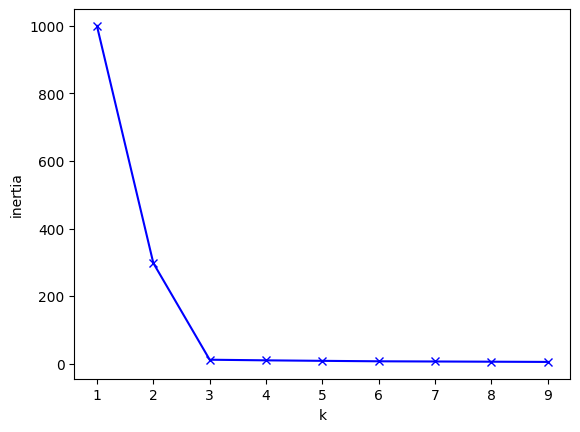

In [10]:
plt.plot(K_range, inertia, 'bx-')
plt.xlabel('k')
plt.ylabel('inertia')
plt.show()
#

In [20]:
kmeans = KMeans(n_clusters=3, random_state=42)

In [21]:
cluster_labels = kmeans.fit_predict(x_scaled)

In [22]:
df['cluster'] = cluster_labels

<Axes: xlabel='feature1', ylabel='feature2'>

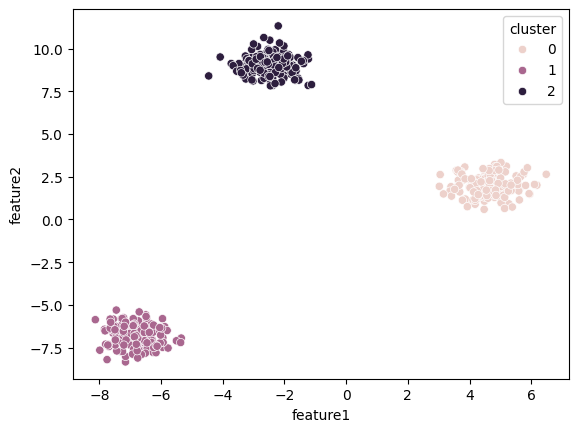

In [23]:
sns.scatterplot(data=df, x='feature1', y='feature2', hue='cluster')
